In [16]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import resnet18, ResNet18_Weights
from ultralytics import YOLO

from classes import RotationCNNGRU
from classes import RotationPositionDataset
from classes import RotationViTGRU

import matplotlib.pyplot as plt


In [5]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

PROJECT_ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "training_runs").is_dir()
)

DATA_ROOT = PROJECT_ROOT / "data" / "singleObjectDetection"

inference_config = {
    "test_video": "GrandmaAlleyWay",
    "trajectory_file": "rotation_000.csv",

    "cnn_gru_checkpoint": (
        PROJECT_ROOT
        / "training_runs"
        / "cpu_20min_test_boats"
        / "checkpoint.pt"
    ),

    "yolo_weights": (
        PROJECT_ROOT
        / "notebooks"
        / "yolo11n.pt"
    ),

    "output_dir": PROJECT_ROOT / "trajectory_results",
    "chunk_size": 16,
    "max_image_size": 128,
    "target_class": "person",
    "yolo_confidence": 0.6,
    "yolo_iou": 0.50,
}

inference_config["output_dir"].mkdir(
    parents=True,
    exist_ok=True,
)

print("Device:", device)

Device: cpu


In [6]:
checkpoint = torch.load(
    inference_config["cnn_gru_checkpoint"],
    map_location=device,
)

training_config = checkpoint["config"]

"""
rotation_model = RotationCNNGRU(
    hidden_size=training_config["hidden_size"]
).to(device)
"""
rotation_model = RotationViTGRU(
    hidden_size=training_config["hidden_size"]
).to(device)


rotation_model.load_state_dict(
    checkpoint["model_state_dict"]
)

rotation_model.eval()


yolo_model = YOLO(
    str(inference_config["yolo_weights"])
)

print("CNN-GRU checkpoint loaded")
print("YOLO model loaded")

CNN-GRU checkpoint loaded
YOLO model loaded


In [7]:
def load_test_trajectory( # Devides the frames and returns cnn frames and yolo frames seperately
    video_dir,
    trajectory_file,
    max_side=128,
):
    trajectory_data = pd.read_csv(trajectory_file)

    cnn_frames = []
    yolo_frames = []
    frame_information = []

    for row in trajectory_data.itertuples(index=False):
        image_path = video_dir / "input" / row.filename

        image = cv2.imread(str(image_path))
        height, width = image.shape[:2]

        rotation_matrix = cv2.getRotationMatrix2D(
            (width / 2, height / 2),
            row.angle_deg,
            row.zoom,
        )

        rotated_image = cv2.warpAffine(
            image,
            rotation_matrix,
            (width, height),
        )

        # YOLO receives the original-resolution rotated image.
        yolo_frames.append(rotated_image)

        # CNN-GRU receives the same resizing used during training.
        scale = max_side / max(height, width)

        new_size = (
            max(8, round(width * scale / 8) * 8),
            max(8, round(height * scale / 8) * 8),
        )

        resized = cv2.resize(rotated_image, new_size)
        resized = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

        cnn_frames.append(resized)

        frame_information.append({
            "filename": row.filename,
            "image_width": width,
            "image_height": height,
        })

    cnn_frames = (
        torch.from_numpy(np.stack(cnn_frames))
        .permute(0, 3, 1, 2)
        .float()
        / 255.0
    )

    frame_information = pd.DataFrame(frame_information)

    # Keep ground truth separate. Do not pass this to either model.
    evaluation_labels = trajectory_data[
        ["filename", "angle_deg", "zoom"]
    ].copy()

    return (
        cnn_frames,
        yolo_frames,
        frame_information,
        evaluation_labels,
    )

In [8]:
video_dir = (
    DATA_ROOT
    / "test"
    / inference_config["test_video"]
)

trajectory_file = (
    video_dir
    / "rotation_labels"
    / inference_config["trajectory_file"]
)

(
    cnn_frames,
    yolo_frames,
    frame_information,
    evaluation_labels,
) = load_test_trajectory(
    video_dir=video_dir,
    trajectory_file=trajectory_file,
    max_side=inference_config["max_image_size"],
)

In [9]:
# CNN-GRU predictions
def predict_rotations(
    cnn_frames,
    frame_information,
    rotation_model,
    device,
    chunk_size=16,
):
    rotation_model.eval()

    reference = cnn_frames[0].to(device)
    hidden = None

    predicted_vectors = []

    with torch.no_grad():
        for start in range(0, len(cnn_frames), chunk_size):
            end = min(start + chunk_size, len(cnn_frames))

            frame_chunk = cnn_frames[start:end].to(device)

            predictions, hidden = rotation_model(
                frames=frame_chunk,
                reference=reference,
                hidden=hidden,
            )
            
            predicted_vectors.append(
                predictions.cpu()
            )

            hidden = hidden.detach()

    predicted_vectors = torch.cat(
        predicted_vectors,
        dim=0,
    )

    predicted_cos = predicted_vectors[:, 0]
    predicted_sin = predicted_vectors[:, 1]

    predicted_angles = torch.rad2deg(
        torch.atan2(
            predicted_sin,
            predicted_cos,
        )
    )

    return pd.DataFrame({
        "filename": frame_information["filename"].to_numpy(),
        "estimated_angle_deg": predicted_angles.numpy(),
        "estimated_cos": predicted_cos.numpy(),
        "estimated_sin": predicted_sin.numpy(),
    })

In [10]:
# Yolo predictions
def predict_object_positions(
    yolo_frames,
    frame_information,
    yolo_model,
    device,
    target_classes=None,
    confidence=0.25,
    iou=0.50,
):
    if target_classes is None:
        allowed_class_ids =None
    else:
        requested_names = {
            name.lower()
            for name in target_classes
        }
        allowed_class_ids = [
            class_id
            for class_id, class_name
            in yolo_model.names.items()
            if class_name.lower() in requested_names
        ]
        missing_names = requested_names - {
            yolo_model.names[class_id].lower()
            for class_id in allowed_class_ids
        }

        if missing_names:
            raise ValueError(
                f"Unknown YOLO classes: {missing_names}"
            )
        
    predictions = yolo_model.predict(
        source=yolo_frames,
        conf=confidence,
        iou=iou,
        classes=allowed_class_ids,
        verbose=False,
        device=str(device),
    )

    rows = []

    for frame_info, prediction in zip(
        frame_information.itertuples(index=False),
        predictions,
    ):
        row = {
            "filename": frame_info.filename,
            "object_detected": False,
            "detected_class": None,
            "detection_confidence": np.nan,
            "x1": np.nan,
            "y1": np.nan,
            "x2": np.nan,
            "y2": np.nan,
            "x_rotated": np.nan,
            "y_rotated": np.nan,
        }

        boxes = prediction.boxes

        if boxes is None or len(boxes) == 0:
            rows.append(row)
            continue

        class_ids = (
            boxes.cls.cpu().numpy().astype(int)
        )

        confidences = boxes.conf.cpu().numpy()
        coordinates = boxes.xyxy.cpu().numpy()

        best_index = int(np.argmax(confidences))

        class_id = class_ids[best_index]
        x1, y1, x2, y2 = coordinates[best_index]
        
        row.update({
            "object_detected": True,
            "detected_class": yolo_model.names[class_id],
            "detection_confidence": confidences[best_index],
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "x_rotated": (x1 + x2) / 2,
            "y_rotated": (y1 + y2) / 2,
        })

        rows.append(row)

    return pd.DataFrame(rows)


In [11]:
def stabilize_frames(
    frames,
    frame_information,
    rotation_results,
):
    angle_lookup = (
        rotation_results
        .set_index("filename")["estimated_angle_deg"]
    )

    stabilized_frames = []

    for frame, frame_info in zip(
        frames,
        frame_information.itertuples(index=False),
    ):
        estimated_angle = angle_lookup.loc[
            frame_info.filename
        ]

        height, width = frame.shape[:2]
        center = (width / 2, height / 2)

        # This represents the rotation predicted by the CNN-GRU.
        estimated_rotation = cv2.getRotationMatrix2D(
            center,
            estimated_angle,
            1.0,
        )

        # Apply its inverse to stabilize the frame.
        inverse_rotation = cv2.invertAffineTransform(
            estimated_rotation
        )

        stabilized_frame = cv2.warpAffine(
            frame,
            inverse_rotation,
            (width, height),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
        )

        stabilized_frames.append(stabilized_frame)

    return stabilized_frames

In [12]:
rotation_results = predict_rotations(
    cnn_frames=cnn_frames,
    frame_information=frame_information,
    rotation_model=rotation_model,
    device=device,
    chunk_size=inference_config["chunk_size"],
)

In [13]:
stabilized_frames = stabilize_frames(
    frames=yolo_frames,
    frame_information=frame_information,
    rotation_results=rotation_results,
)

print("Stabilized frames:", len(stabilized_frames))

Stabilized frames: 189


In [18]:
# Plot function
def show_stabilization(frame_index):
    original = yolo_frames[frame_index]
    stabilized = stabilized_frames[frame_index]

    estimated_angle = rotation_results.iloc[
        frame_index
    ]["estimated_angle_deg"]

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6),
    )

    axes[0].imshow(
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    )
    axes[0].set_title("Rotated input")
    axes[0].axis("off")

    axes[1].imshow(
        cv2.cvtColor(stabilized, cv2.COLOR_BGR2RGB)
    )
    axes[1].set_title(
        f"Stabilized image\n"
        f"Estimated angle: {estimated_angle:.1f}°"
    )
    axes[1].axis("off")

    plt.show()

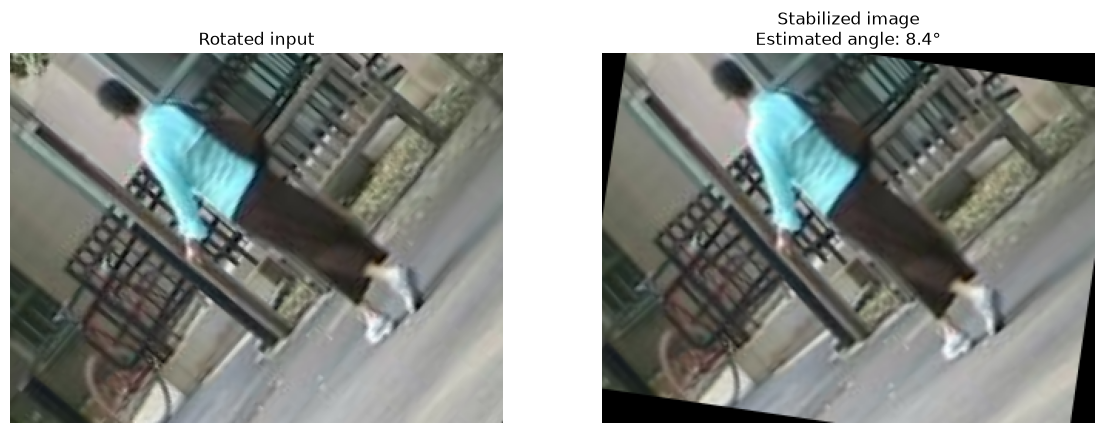

In [20]:
show_stabilization(70)

In [21]:
raw_yolo_results = predict_object_positions(
    yolo_frames=yolo_frames,
    frame_information=frame_information,
    yolo_model=yolo_model,
    device=device,
    target_classes=["person"],
    confidence=0.6,
    iou=inference_config["yolo_iou"],
)

stabilized_yolo_results = predict_object_positions(
    yolo_frames=stabilized_frames,
    frame_information=frame_information,
    yolo_model=yolo_model,
    device=device,
    target_classes=["person"],
    confidence=0.6,
    iou=inference_config["yolo_iou"],
)

stabilized_yolo_results = stabilized_yolo_results.rename(
    columns={
        "x_rotated": "x_flattened",
        "y_rotated": "y_flattened",
    }
)

raw_comparison = raw_yolo_results[
    [
        "filename",
        "object_detected",
        "detected_class",
        "detection_confidence",
        "x_rotated",
        "y_rotated",
    ]
].rename(
    columns={
        "object_detected": "raw_detected",
        "detected_class": "raw_class",
        "detection_confidence": "raw_confidence",
        "x_rotated": "raw_x",
        "y_rotated": "raw_y",
    }
)

stabilized_comparison = stabilized_yolo_results[
    [
        "filename",
        "object_detected",
        "detected_class",
        "detection_confidence",
        "x_flattened",
        "y_flattened",
    ]
].rename(
    columns={
        "object_detected": "stabilized_detected",
        "detected_class": "stabilized_class",
        "detection_confidence": "stabilized_confidence",
        "x_flattened": "stabilized_x",
        "y_flattened": "stabilized_y",
    }
)

frame_indices = (
    frame_information
    .reset_index()
    .rename(columns={"index": "frame_index"})
)

yolo_comparison = (
    frame_indices
    .merge(
        evaluation_labels[
            ["filename", "angle_deg"]
        ],
        on="filename",
        validate="one_to_one",
    )
    .merge(
        rotation_results[
            ["filename", "estimated_angle_deg"]
        ],
        on="filename",
        validate="one_to_one",
    )
    .merge(
        raw_comparison,
        on="filename",
        validate="one_to_one",
    )
    .merge(
        stabilized_comparison,
        on="filename",
        validate="one_to_one",
    )
)


In [22]:
raw_comparison = raw_yolo_results[
    [
        "filename",
        "object_detected",
        "detected_class",
        "detection_confidence",
        "x_rotated",
        "y_rotated",
    ]
].rename(
    columns={
        "object_detected": "raw_detected",
        "detected_class": "raw_class",
        "detection_confidence": "raw_confidence",
        "x_rotated": "raw_x",
        "y_rotated": "raw_y",
    }
)

stabilized_comparison = stabilized_yolo_results[
    [
        "filename",
        "object_detected",
        "detected_class",
        "detection_confidence",
        "x_flattened",
        "y_flattened",
    ]
].rename(
    columns={
        "object_detected": "stabilized_detected",
        "detected_class": "stabilized_class",
        "detection_confidence": "stabilized_confidence",
        "x_flattened": "stabilized_x",
        "y_flattened": "stabilized_y",
    }
)

frame_indices = (
    frame_information
    .reset_index()
    .rename(columns={"index": "frame_index"})
)

yolo_comparison = (
    frame_indices
    .merge(
        evaluation_labels[
            ["filename", "angle_deg"]
        ],
        on="filename",
        validate="one_to_one",
    )
    .merge(
        rotation_results[
            ["filename", "estimated_angle_deg"]
        ],
        on="filename",
        validate="one_to_one",
    )
    .merge(
        raw_comparison,
        on="filename",
        validate="one_to_one",
    )
    .merge(
        stabilized_comparison,
        on="filename",
        validate="one_to_one",
    )
)

In [23]:
yolo_comparison["outcome"] = np.select(
    [
        (
            yolo_comparison["raw_detected"]
            & yolo_comparison["stabilized_detected"]
        ),
        (
            ~yolo_comparison["raw_detected"]
            & yolo_comparison["stabilized_detected"]
        ),
        (
            yolo_comparison["raw_detected"]
            & ~yolo_comparison["stabilized_detected"]
        ),
    ],
    [
        "Detected in both",
        "Gained after stabilization",
        "Lost after stabilization",
    ],
    default="Missed in both",
)

both_detected = (
    yolo_comparison["raw_detected"]
    & yolo_comparison["stabilized_detected"]
)

yolo_comparison["confidence_change"] = np.where(
    both_detected,
    (
        yolo_comparison["stabilized_confidence"]
        - yolo_comparison["raw_confidence"]
    ),
    np.nan,
)

display(
    yolo_comparison[
        [
            "frame_index",
            "filename",
            "angle_deg",
            "estimated_angle_deg",
            "raw_detected",
            "raw_confidence",
            "stabilized_detected",
            "stabilized_confidence",
            "confidence_change",
            "outcome",
        ]
    ].style.format(
        {
            "angle_deg": "{:.1f}",
            "estimated_angle_deg": "{:.1f}",
            "raw_confidence": "{:.3f}",
            "stabilized_confidence": "{:.3f}",
            "confidence_change": "{:+.3f}",
        },
        na_rep="—",
    )
)

,frame_index,filename,angle_deg,estimated_angle_deg,raw_detected,raw_confidence,stabilized_detected,stabilized_confidence,confidence_change,outcome
0,0,in001367.jpg,0.0,8.4,False,—,False,—,—,Missed in both
1,1,in001368.jpg,0.5,8.4,False,—,False,—,—,Missed in both
2,2,in001369.jpg,0.4,8.4,False,—,False,—,—,Missed in both
3,3,in001370.jpg,2.9,8.4,False,—,False,—,—,Missed in both
4,4,in001371.jpg,5.4,8.4,False,—,False,—,—,Missed in both
5,5,in001372.jpg,5.4,8.4,False,—,False,—,—,Missed in both
6,6,in001373.jpg,6.9,8.4,False,—,False,—,—,Missed in both
7,7,in001374.jpg,13.3,8.4,False,—,False,—,—,Missed in both
8,8,in001375.jpg,22.6,8.4,False,—,False,—,—,Missed in both
9,9,in001376.jpg,27.6,8.4,False,—,False,—,—,Missed in both


In [24]:
def summarize_yolo_results(name, results):
    detected = results["object_detected"]

    return {
        "Input": name,
        "Detected frames": int(detected.sum()),
        "Total frames": len(results),
        "Detection rate": detected.mean(),
        "Mean confidence": results.loc[
            detected,
            "detection_confidence",
        ].mean(),
        "Median confidence": results.loc[
            detected,
            "detection_confidence",
        ].median(),
    }


yolo_summary = pd.DataFrame([
    summarize_yolo_results(
        "Raw rotated frames",
        raw_yolo_results,
    ),
    summarize_yolo_results(
        "CNN-GRU stabilized frames",
        stabilized_yolo_results,
    ),
])

display(
    yolo_summary.style.format(
        {
            "Detection rate": "{:.1%}",
            "Mean confidence": "{:.3f}",
            "Median confidence": "{:.3f}",
        }
    )
)

,Input,Detected frames,Total frames,Detection rate,Mean confidence,Median confidence
0,Raw rotated frames,37,189,19.6%,0.817,0.848
1,CNN-GRU stabilized frames,43,189,22.8%,0.808,0.831


In [25]:
#plot function
def show_model_inputs(frame_index):
    cnn_image = (
        cnn_frames[frame_index]
        .permute(1, 2, 0)
        .numpy()
    )

    actual_yolo_input = cv2.cvtColor(
        stabilized_frames[frame_index],
        cv2.COLOR_BGR2RGB,
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 5),
    )

    axes[0].imshow(cnn_image)
    axes[0].set_title("CNN-GRU input")

    axes[1].imshow(actual_yolo_input)
    axes[1].set_title("Actual YOLO input")

    for axis in axes:
        axis.axis("off")

    plt.tight_layout()
    plt.show()

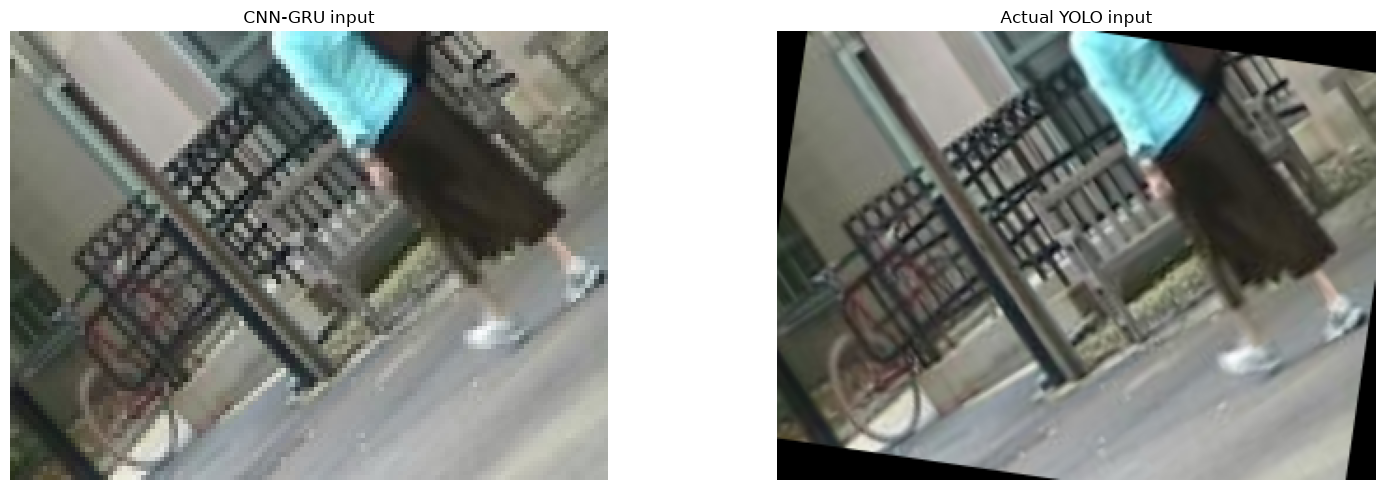

In [26]:
show_model_inputs(50)

In [27]:
flattened_results = (
    frame_information
    .merge(
        rotation_results,
        on="filename",
        validate="one_to_one",
    )
    .merge(
        stabilized_yolo_results,
        on="filename",
        validate="one_to_one",
    )
)

flattened_results.head()

assert len(flattened_results) == len(frame_information)

display(flattened_results.head())

,filename,image_width,image_height,estimated_angle_deg,estimated_cos,estimated_sin,object_detected,detected_class,detection_confidence,x1,y1,x2,y2,x_flattened,y_flattened
0,in001367.jpg,320,240,8.421278,0.989218,0.14645,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,in001368.jpg,320,240,8.421283,0.989218,0.14645,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,in001369.jpg,320,240,8.421283,0.989218,0.14645,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,in001370.jpg,320,240,8.421283,0.989218,0.14645,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,in001371.jpg,320,240,8.421283,0.989218,0.14645,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
output_path = (
    inference_config["output_dir"]
    / (
        f"{inference_config['test_video']}_"
        f"{Path(inference_config['trajectory_file']).stem}_"
        "model_results.csv"
    )
)

flattened_results.to_csv(
    output_path,
    index=False,
)

print("Saved:", output_path)

Saved: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/trajectory_results/GrandmaAlleyWay_rotation_000_model_results.csv


In [29]:
inspection_confidence = 0.6

inspection_results = yolo_model.predict(
    source=stabilized_frames,
    conf=inspection_confidence,
    iou=inference_config["yolo_iou"],
    verbose=False,
    device=str(device),
)

print("Frames processed:", len(inspection_results))

Frames processed: 189


In [30]:
# Plot function
from IPython.display import display


def inspect_yolo_frame(frame_index):
    image = yolo_frames[frame_index]
    result = inspection_results[frame_index]
    filename = frame_information.iloc[frame_index]["filename"]

    # Ultralytics returns its plotted image in BGR format.
    annotated_image = result.plot(
        labels=True,
        conf=True,
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6),
    )

    axes[0].imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    axes[0].set_title(
        f"Rotated input\n{filename}"
    )
    axes[0].axis("off")

    axes[1].imshow(
        cv2.cvtColor(
            annotated_image,
            cv2.COLOR_BGR2RGB,
        )
    )
    axes[1].set_title(
        f"YOLO detections\n"
        f"minimum confidence = {inspection_confidence}"
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        print("No detections")
        return pd.DataFrame()

    class_ids = boxes.cls.cpu().numpy().astype(int)
    confidences = boxes.conf.cpu().numpy()
    coordinates = boxes.xyxy.cpu().numpy()

    rows = []

    for class_id, confidence, coordinates_xyxy in zip(
        class_ids,
        confidences,
        coordinates,
    ):
        x1, y1, x2, y2 = coordinates_xyxy

        rows.append({
            "class": yolo_model.names[class_id],
            "confidence": confidence,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "center_x": (x1 + x2) / 2,
            "center_y": (y1 + y2) / 2,
        })

    detection_table = pd.DataFrame(rows)
    detection_table = detection_table.sort_values(
        "confidence",
        ascending=False,
    )

    display(detection_table.round(3))

    return detection_table

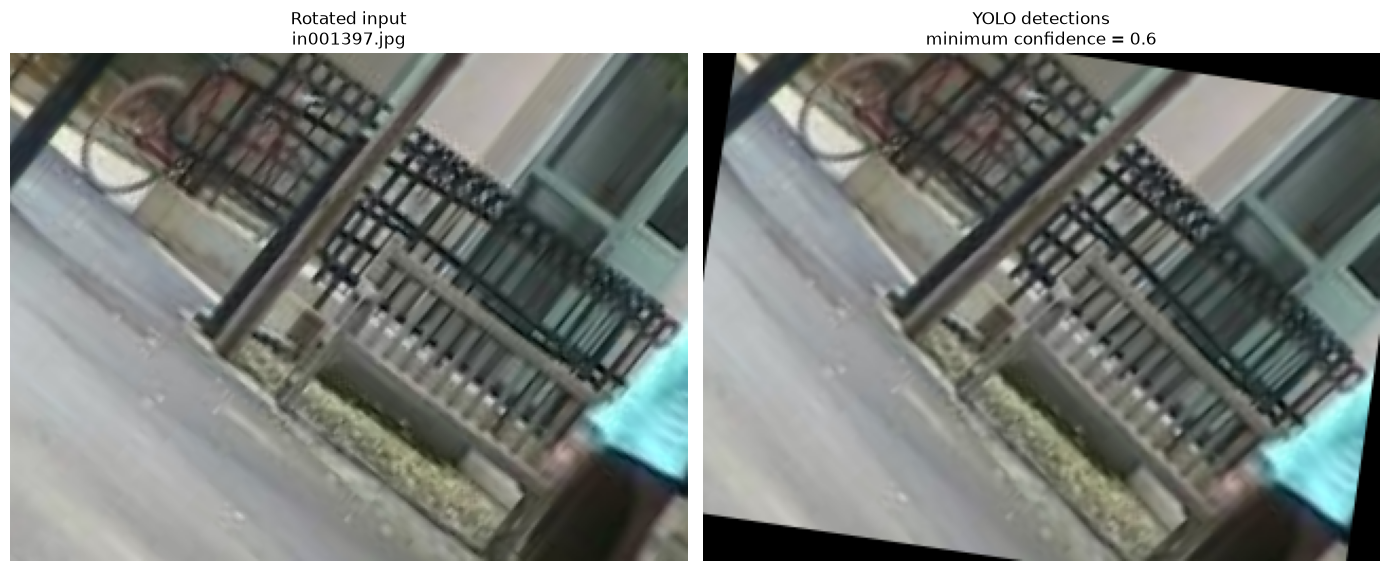

No detections


""


In [31]:
inspect_yolo_frame(30)

In [32]:


raw_detection_rate = (
    raw_yolo_results["object_detected"].mean()
)

stabilized_detection_rate = (
    stabilized_yolo_results["object_detected"].mean()
)

raw_mean_confidence = (
    raw_yolo_results.loc[
        raw_yolo_results["object_detected"],
        "detection_confidence",
    ].mean()
)

stabilized_mean_confidence = (
    stabilized_yolo_results.loc[
        stabilized_yolo_results["object_detected"],
        "detection_confidence",
    ].mean()
)

print(f"Raw detection rate: {raw_detection_rate:.1%}")
print(
    f"Stabilized detection rate: "
    f"{stabilized_detection_rate:.1%}"
)
print(f"Raw confidence: {raw_mean_confidence:.3f}")
print(
    f"Stabilized confidence: "
    f"{stabilized_mean_confidence:.3f}"
)

Raw detection rate: 19.6%
Stabilized detection rate: 22.8%
Raw confidence: 0.817
Stabilized confidence: 0.808


In [35]:
angle_evaluation = rotation_results.merge(
    evaluation_labels,
    on="filename",
    validate="one_to_one",
)

angle_evaluation["angle_error_deg"] = (
    (
        angle_evaluation["estimated_angle_deg"]
        - angle_evaluation["angle_deg"]
        + 180
    )
    % 360
    - 180
)

angle_mae = (
    angle_evaluation["angle_error_deg"]
    .abs()
    .mean()
)

print(f"Angle MAE: {angle_mae:.2f}°")

Angle MAE: 29.67°


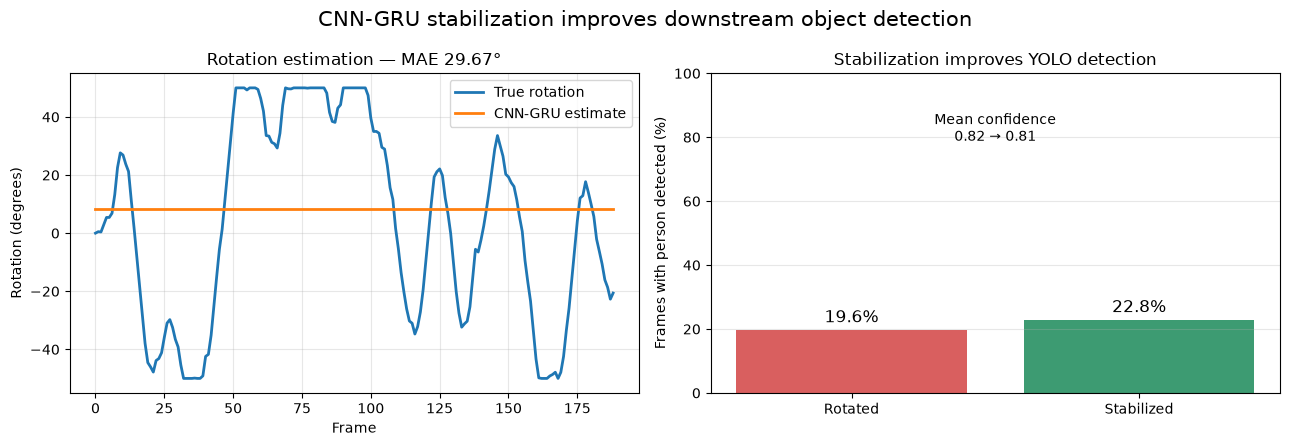

Saved: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/trajectory_results/validation_summary.png


In [36]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

# Angle estimation
axes[0].plot(
    angle_evaluation["angle_deg"],
    label="True rotation",
    linewidth=2,
)

axes[0].plot(
    angle_evaluation["estimated_angle_deg"],
    label="CNN-GRU estimate",
    linewidth=2,
)

axes[0].set_title(
    f"Rotation estimation — MAE {angle_mae:.2f}°"
)
axes[0].set_xlabel("Frame")
axes[0].set_ylabel("Rotation (degrees)")
axes[0].legend()
axes[0].grid(alpha=0.3)


# YOLO detection comparison
labels = ["Rotated", "Stabilized"]
detection_rates = [
    raw_detection_rate * 100,
    stabilized_detection_rate * 100,
]

bars = axes[1].bar(
    labels,
    detection_rates,
    color=["#d95f5f", "#3d9b72"],
)

axes[1].bar_label(
    bars,
    fmt="%.1f%%",
    padding=3,
    fontsize=12,
)

axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Frames with person detected (%)")
axes[1].set_title("Stabilization improves YOLO detection")
axes[1].grid(axis="y", alpha=0.3)

axes[1].text(
    0.5,
    0.88,
    (
        f"Mean confidence\n"
        f"{raw_mean_confidence:.2f} → "
        f"{stabilized_mean_confidence:.2f}"
    ),
    transform=axes[1].transAxes,
    ha="center",
    va="top",
)

fig.suptitle(
    "CNN-GRU stabilization improves downstream object detection",
    fontsize=15,
)

plt.tight_layout()

poster_figure_path = (
    inference_config["output_dir"]
    / "validation_summary.png"
)

plt.savefig(
    poster_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", poster_figure_path)